#  **AI-Based Predictive Modeling of Individual Carbon Footprints Using Behavioral and Energy Consumption Data**

This version uses the synthetic `carbon_footprint_dataset.csv` (18,000 rows, 50 features) instead of the Kaggle dataset, and fixes the issues flagged in review:
- preprocessing (imputation, outlier clipping, encoding) is fit **only on the training data**, inside `sklearn` Pipelines, so nothing from the test set leaks into training
- all three models (RandomForest, XGBoost, MLP) get the same 5-fold cross-validation, not just the MLP
- SHAP uses `TreeExplainer` directly (fast, exact for tree models) instead of the slow generic `Explainer`
- the correlation heatmap colour scale is fixed to show negative correlations correctly
- adds residual diagnostics and saves the best pipeline with `joblib`

### 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor
import shap

RANDOM_STATE = 42

In [2]:
# keep_default_na=False + explicit na_values avoids a real bug: pandas' default
# NA-detection treats the literal string "None" as missing, but this dataset has
# real categories named "None" (Heating_Energy_Source, Cooling_AC_Usage - meaning
# "no heating"/"no AC", which is informative, not missing). Without this fix,
# ~25% of Cooling_AC_Usage was silently turned into fake NaNs on load.
data = pd.read_csv("/content/carbon_footprint_dataset (1).csv", keep_default_na=False, na_values=[""])
print(data.shape)
data.head()

(18000, 51)


,Respondent_ID,Age,Gender,Household_Size,Education_Level,Occupation_Type,Household_Income_Level,Marital_Status,Residence_Type,Dwelling_Type,...,Indoor_Temperature_C,Indoor_Humidity_pct,Renewable_Energy_Solar,Daily_AI_Chatbot_Queries,Avg_Query_Type,AI_Model_Type,Daily_Screen_Time_AI_Work_hours,Cloud_Storage_Streaming_GB_month,Estimated_AI_Energy_Use_Wh_day,Carbon_Footprint_kgCO2_year
0,1,59,Female,4,Bachelor's degree,Student,Lower-Middle,Single,Rural,Semi-detached house,...,19.8,52.1,No,11,Long (text),Standard model,0.98,105.8,26.04,9676.4
1,2,36,Female,4,Bachelor's degree,Employed - Office/Professional,High,Married,Suburban,Semi-detached house,...,19.4,56.2,Yes,16,Long (text),Standard model,1.85,144.1,36.66,5004.9
2,3,66,Male,2,No formal education,Employed - Office/Professional,Upper-Middle,Widowed,Urban,Apartment,...,20.5,47.3,No,14,Short (text),Standard model,2.53,73.8,9.03,10653.7
3,4,70,Female,3,Master's degree,Retired,Lower-Middle,Widowed,Suburban,Detached house,...,17.1,37.7,No,10,Short (text),Standard model,1.83,102.3,2.17,4521.3
4,5,21,Female,3,High school,Unemployed,Upper-Middle,Married,Urban,Apartment,...,20.4,48.6,No,20,Long (text),Standard model,5.01,175.2,44.71,6881.8


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 51 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Respondent_ID                              18000 non-null  int64  
 1   Age                                        18000 non-null  int64  
 2   Gender                                     18000 non-null  object 
 3   Household_Size                             18000 non-null  int64  
 4   Education_Level                            18000 non-null  object 
 5   Occupation_Type                            18000 non-null  object 
 6   Household_Income_Level                     18000 non-null  object 
 7   Marital_Status                             18000 non-null  object 
 8   Residence_Type                             18000 non-null  object 
 9   Dwelling_Type                              18000 non-null  object 
 10  Floor_Area_m2         

In [4]:
data.describe()

,Respondent_ID,Age,Household_Size,Floor_Area_m2,Number_of_Rooms,Building_Age_Years,Number_of_Vehicles,Monthly_Vehicle_Distance_km,Commute_Distance_km,Air_Travel_Frequency_per_year,...,Energy_Saving_Habit_Score,Real_Time_Electricity_Consumption_kWh_day,Number_Connected_Smart_Devices,Indoor_Temperature_C,Indoor_Humidity_pct,Daily_AI_Chatbot_Queries,Daily_Screen_Time_AI_Work_hours,Cloud_Storage_Streaming_GB_month,Estimated_AI_Energy_Use_Wh_day,Carbon_Footprint_kgCO2_year
count,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,18000.000000,17460.000000,18000.000000,...,18000.000000,18000.000000,18000.000000,18000.000000,17640.000000,18000.000000,18000.000000,17730.000000,18000.000000,18000.000000
mean,9000.500000,53.682833,3.606167,119.012178,4.257167,20.150833,1.218389,776.294556,13.645223,2.422111,...,5.041606,5.734099,3.299611,20.981489,44.978452,13.166111,1.739859,88.186960,88.549371,7612.386539
std,5196.296758,16.445524,1.602597,43.726295,1.689797,20.067495,0.958223,555.674879,12.441349,1.844514,...,1.967795,3.337460,2.818876,2.003514,10.083277,4.221895,1.211940,33.727351,213.811764,2350.584137
min,1.000000,18.000000,1.000000,28.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,2.000000,0.000000,14.000000,15.000000,1.000000,0.000000,0.000000,0.000000,697.500000
25%,4500.750000,42.000000,2.000000,85.200000,3.000000,6.000000,1.000000,292.000000,4.500000,1.000000,...,3.700000,2.910000,1.000000,19.600000,38.200000,10.000000,0.760000,65.100000,7.310000,5910.750000
50%,9000.500000,54.000000,3.000000,114.400000,4.000000,14.000000,1.000000,809.000000,10.400000,2.000000,...,5.000000,5.170000,2.000000,21.000000,44.900000,13.000000,1.660000,87.700000,17.510000,7511.550000
75%,13500.250000,65.000000,5.000000,151.700000,5.000000,28.000000,2.000000,1191.000000,18.700000,4.000000,...,6.400000,7.650000,5.000000,22.300000,51.900000,16.000000,2.560000,111.200000,66.690000,9176.825000
max,18000.000000,90.000000,8.000000,267.000000,10.000000,130.000000,5.000000,2685.000000,108.300000,13.000000,...,10.000000,23.870000,16.000000,28.000000,80.000000,32.000000,6.190000,213.100000,2143.160000,17076.100000


In [5]:
# Missing values (this dataset has ~1.5-3% injected missingness in 4 columns,
# to mimic real survey data)
print(data.isna().sum()[data.isna().sum() > 0])

Commute_Distance_km                 540
Monthly_Grocery_Bill_USD            360
Indoor_Humidity_pct                 360
Cloud_Storage_Streaming_GB_month    270
dtype: int64


### 2. Train/Test Split — done *before* any cleaning

This is the key leakage fix from the review: medians, outlier bounds, and one-hot categories must only ever be learned from the training data. Splitting first, then putting every cleaning step inside a `Pipeline`, guarantees that.

In [6]:
# Respondent_ID is just a row identifier, not a predictive feature
data = data.drop(columns=["Respondent_ID"])

TARGET = "Carbon_Footprint_kgCO2_year"
X = data.drop(columns=[TARGET])
y = data[TARGET]

# Check target skew before splitting (informational only - doesn't touch test data)
print("Target skew:", y.skew().round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

Target skew: 0.268
(14400, 49) (3600, 49)


### 3. Preprocessing Pipeline

- **Numeric columns:** median imputation + IQR outlier clipping — both fit on the training fold only (via `Pipeline`), so the same transform used for `X_test` never "saw" test values.
- **Categorical columns:** most-frequent imputation + one-hot encoding, `handle_unknown="ignore"` so any category that only appears in the test set doesn't crash the pipeline.

Wrapping this in a `ColumnTransformer` means the *exact same* preprocessing logic gets reused for every model below, and — importantly — gets refit correctly inside every cross-validation fold.

In [7]:
categorical_cols = [
    "Gender", "Education_Level", "Occupation_Type", "Household_Income_Level",
    "Marital_Status", "Residence_Type", "Dwelling_Type", "Ownership_Status",
    "Heating_Energy_Source", "Cooling_AC_Usage", "Insulation_Rating",
    "Primary_Transport_Mode", "Vehicle_Fuel_Type", "Diet_Type", "Food_Waste_Level",
    "Recycling_Behavior_Frequency", "Smart_Thermostat_Usage",
    "Smart_Lighting_Automation_Usage", "Renewable_Energy_Solar",
    "Avg_Query_Type", "AI_Model_Type",
]

numeric_cols = [c for c in X.columns if c not in categorical_cols]
print(f"{len(categorical_cols)} categorical columns, {len(numeric_cols)} numeric columns")

21 categorical columns, 28 numeric columns


In [8]:
class IQRClipper(BaseEstimator, TransformerMixin):
    """Clips numeric columns to [Q1 - 1.5*IQR, Q3 + 1.5*IQR], learned from fit() data only."""
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.low_ = q1 - self.factor * iqr
        self.high_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        X = pd.DataFrame(X).reset_index(drop=True)
        return X.clip(lower=self.low_, upper=self.high_, axis=1).values

    def get_feature_names_out(self, input_features=None):
        # A clip step doesn't rename/drop/add columns, so pass through whatever
        # names the previous pipeline step (the imputer) reports. This is what
        # makes Pipeline.get_feature_names_out() work end-to-end through this
        # custom step - without it, ColumnTransformer.get_feature_names_out()
        # raises AttributeError on this step.
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        return np.asarray([f"x{i}" for i in range(self.low_.shape[0])], dtype=object)

In [9]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("clip", IQRClipper()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

# Columns that genuinely have missing values (checked earlier in section 1).
# A "this value was missing" flag is often informative in its own right (e.g. if
# non-response correlates with the target), so it's added as an extra feature
# rather than just silently filled in and forgotten. Kept as its own branch,
# separate from IQRClipper, since clipping would corrupt these 0/1 flags.
missing_flag_cols = data.columns[data.isna().any()].intersection(numeric_cols).tolist()
print("Adding missingness indicators for:", missing_flag_cols)

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
    ("missing_flags", MissingIndicator(features="all"), missing_flag_cols),
])

Adding missingness indicators for: ['Commute_Distance_km', 'Monthly_Grocery_Bill_USD', 'Indoor_Humidity_pct', 'Cloud_Storage_Streaming_GB_month']


### 4. Model Training

Each model is wrapped in its own `Pipeline` with the *same* `preprocessor` step. The MLP additionally needs scaling, so it gets a `StandardScaler` after the shared preprocessing (note: `with_mean=True`, the default — the original notebook's `with_mean=False` was weakening the standardization for no reason, since the data here isn't sparse).

In [10]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1,
        min_samples_leaf=2, max_features="sqrt",
        max_depth=18,  # caps tree depth/leaf count - keeps accuracy similar
                        # but makes SHAP's TreeExplainer far cheaper to run
                        # (its cost scales with depth^2 x leaves x trees x rows)
    )),
])

xgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", XGBRegressor(
        n_estimators=800, learning_rate=0.05, max_depth=6,
        subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1
    )),
])

mlp_pipe = Pipeline([
    ("prep", preprocessor),
    ("scale", StandardScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(256, 128, 64), activation="relu", solver="adam",
        alpha=1e-4, learning_rate_init=1e-3, max_iter=500,
        random_state=RANDOM_STATE, early_stopping=True,
        n_iter_no_change=20, validation_fraction=0.1
    )),
])

pipelines = {"RandomForest": rf_pipe, "XGBoost": xgb_pipe, "NeuralNet (MLP)": mlp_pipe}

In [11]:
def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

results = []
fitted = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(evaluate(name, y_test, pipe.predict(X_test)))

res = pd.DataFrame(results).sort_values("R2", ascending=False)
print("\n=== Model Comparison (Test Set) ===")
print(res.to_string(index=False))

best_name = res.iloc[0]["Model"]
print("\nBest Model:", best_name)


=== Model Comparison (Test Set) ===
          Model       R2         MAE        RMSE
        XGBoost 0.892259  611.058737  764.313617
NeuralNet (MLP) 0.883911  637.910243  793.371545
   RandomForest 0.706168 1003.830624 1262.207780

Best Model: XGBoost


In [12]:
# Train vs test R2 - overfitting check
for name, pipe in fitted.items():
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    test_r2 = r2_score(y_test, pipe.predict(X_test))
    print(f"{name:16s}  Train R2: {train_r2:.4f}   Test R2: {test_r2:.4f}   Gap: {train_r2-test_r2:.4f}")

RandomForest      Train R2: 0.9208   Test R2: 0.7062   Gap: 0.2147
XGBoost           Train R2: 0.9812   Test R2: 0.8923   Gap: 0.0889
NeuralNet (MLP)   Train R2: 0.9285   Test R2: 0.8839   Gap: 0.0446


### 5. Cross-Validation — now consistent across all three models

The original notebook only ran 5-fold CV for the MLP, so the comparison in the results table above rested on a single train/test split for RandomForest and XGBoost. Because each model here is a full `Pipeline`, `cross_val_score` correctly refits the preprocessing (imputer, clipper, encoder) on each fold's training portion only — no leakage between folds either.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="r2", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:16s}  CV R2 scores: {np.round(scores, 4)}   Mean: {scores.mean():.4f}   Std: {scores.std():.4f}")

RandomForest      CV R2 scores: [0.7071 0.6968 0.6956 0.7044 0.7008]   Mean: 0.7009   Std: 0.0044


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


XGBoost           CV R2 scores: [0.8916 0.8853 0.8857 0.8893 0.8872]   Mean: 0.8878   Std: 0.0024
NeuralNet (MLP)   CV R2 scores: [0.8846 0.8794 0.8772 0.8745 0.8853]   Mean: 0.8802   Std: 0.0042


### 5b. Hyperparameter Tuning

The models above use fixed, hand-picked hyperparameters. `RandomizedSearchCV` searches a range of settings using the same leak-free `Pipeline` (so the search itself never sees the held-out test set either). This mainly targets **RandomForest**, which is well behind the other two models (R² ≈ 0.71 vs ≈ 0.88) — its current `max_depth=18` cap (added earlier to keep SHAP fast) may be too restrictive; the search can trade a bit of SHAP speed for accuracy if a deeper tree turns out to help. **XGBoost** gets a lighter search too, since it's already the front-runner and closest to the ≈0.91 ceiling set by the injected noise.

**Note on runtime:** this cell fits many pipelines end-to-end and can genuinely take a while (minutes, not seconds) on 18,000 rows — the search space deliberately avoids `max_depth=None` (unbounded trees), since that's the single biggest source of slowness. If it's still too slow on your machine, lower `n_iter` and/or `cv` below.

In [14]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [14, 18, 24, 32],   # no None here - unbounded trees are very slow to search over
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5, 0.8],
}
rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist, n_iter=8, cv=3, scoring="r2",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print("Best RF CV R2:", round(rf_search.best_score_, 4))

xgb_param_dist = {
    "model__n_estimators": [500, 800, 1200],
    "model__max_depth": [4, 6, 8],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__subsample": [0.7, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.9, 1.0],
    "model__reg_lambda": [0.5, 1.0, 2.0],
}
xgb_search = RandomizedSearchCV(
    xgb_pipe, xgb_param_dist, n_iter=10, cv=3, scoring="r2",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
xgb_search.fit(X_train, y_train)
print("Best XGB params:", xgb_search.best_params_)
print("Best XGB CV R2:", round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best RF params: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 18}
Best RF CV R2: 0.7663
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGB params: {'model__subsample': 0.7, 'model__reg_lambda': 0.5, 'model__n_estimators': 500, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}
Best XGB CV R2: 0.8888


In [15]:
# Swap in the tuned versions and re-evaluate on the held-out test set
fitted["RandomForest"] = rf_search.best_estimator_
fitted["XGBoost"] = xgb_search.best_estimator_
pipelines["RandomForest"] = rf_search.best_estimator_
pipelines["XGBoost"] = xgb_search.best_estimator_

tuned_results = [evaluate(name, y_test, pipe.predict(X_test)) for name, pipe in fitted.items()]
tuned_res = pd.DataFrame(tuned_results).sort_values("R2", ascending=False)
print("=== Model Comparison After Tuning (Test Set) ===")
print(tuned_res.to_string(index=False))

best_name = tuned_res.iloc[0]["Model"]
best_pipe = fitted[best_name]
print("\nBest Model:", best_name)

=== Model Comparison After Tuning (Test Set) ===
          Model       R2        MAE        RMSE
        XGBoost 0.897010 595.963055  747.274244
NeuralNet (MLP) 0.883911 637.910243  793.371545
   RandomForest 0.783879 859.884296 1082.506346

Best Model: XGBoost


### 6. SHAP Explainability

Using `shap.TreeExplainer` directly (instead of the generic `shap.Explainer`, which fell back to a slow permutation-based method and took ~24 minutes on the RandomForest in the original notebook). `TreeExplainer` is exact and fast for tree-based models — but its cost still scales with tree depth² x leaves x trees x rows explained, so two more things keep it fast here: the RandomForest above now has a `max_depth` cap, and SHAP is computed on a **random sample** of the test set rather than all of it. A few hundred rows is already enough for a stable summary/beeswarm plot — SHAP doesn't need every row the way the R²/MAE metrics do.

In [16]:
SHAP_SAMPLE_SIZE = 500
X_test_sample = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=RANDOM_STATE)
print(f"Explaining {len(X_test_sample)} of {len(X_test)} test rows")

Explaining 500 of 3600 test rows


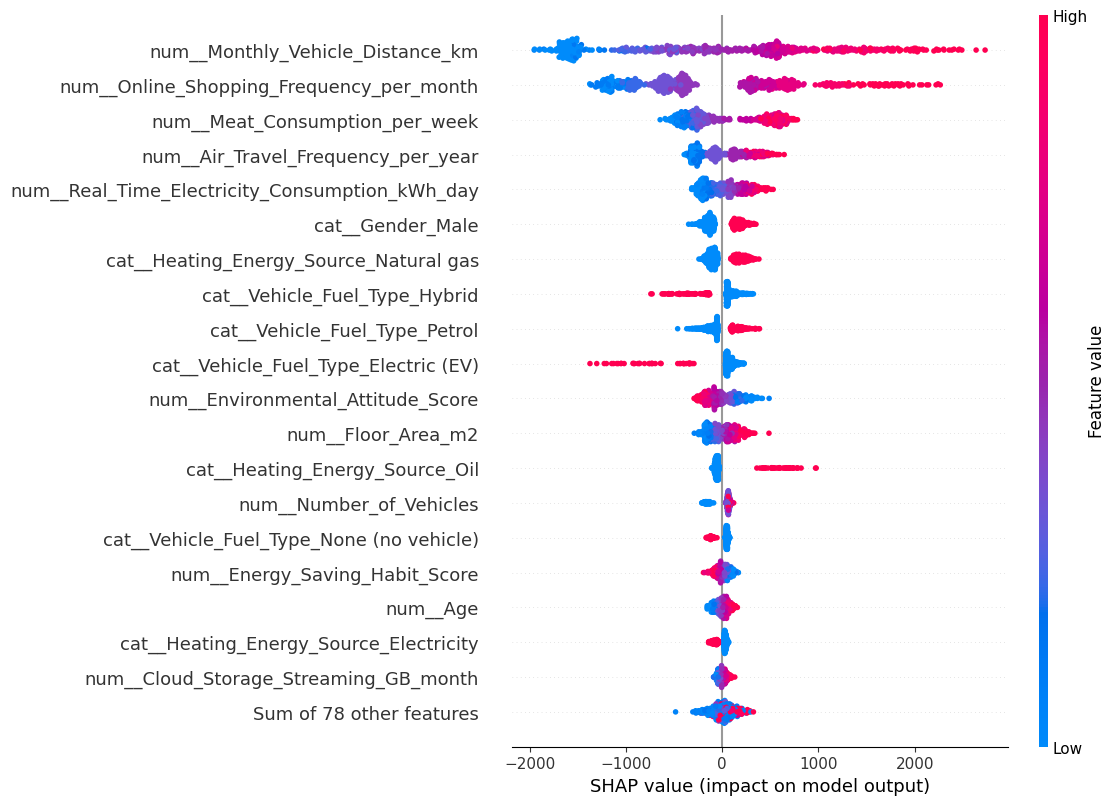


Top 20 features driving Carbon_Footprint_kgCO2_year (RandomForest):

num__Monthly_Vehicle_Distance_km                  1012.553819
num__Online_Shopping_Frequency_per_month           783.849130
num__Meat_Consumption_per_week                     384.401902
num__Air_Travel_Frequency_per_year                 234.476772
num__Real_Time_Electricity_Consumption_kWh_day     170.571632
cat__Gender_Male                                   159.237796
cat__Heating_Energy_Source_Natural gas             143.362627
cat__Vehicle_Fuel_Type_Hybrid                      133.424321
cat__Vehicle_Fuel_Type_Petrol                      132.800195
cat__Vehicle_Fuel_Type_Electric (EV)               132.540010
num__Environmental_Attitude_Score                  131.369045
num__Floor_Area_m2                                 113.118221
cat__Heating_Energy_Source_Oil                     109.136544
num__Number_of_Vehicles                             82.626551
cat__Vehicle_Fuel_Type_None (no vehicle)            62.067831


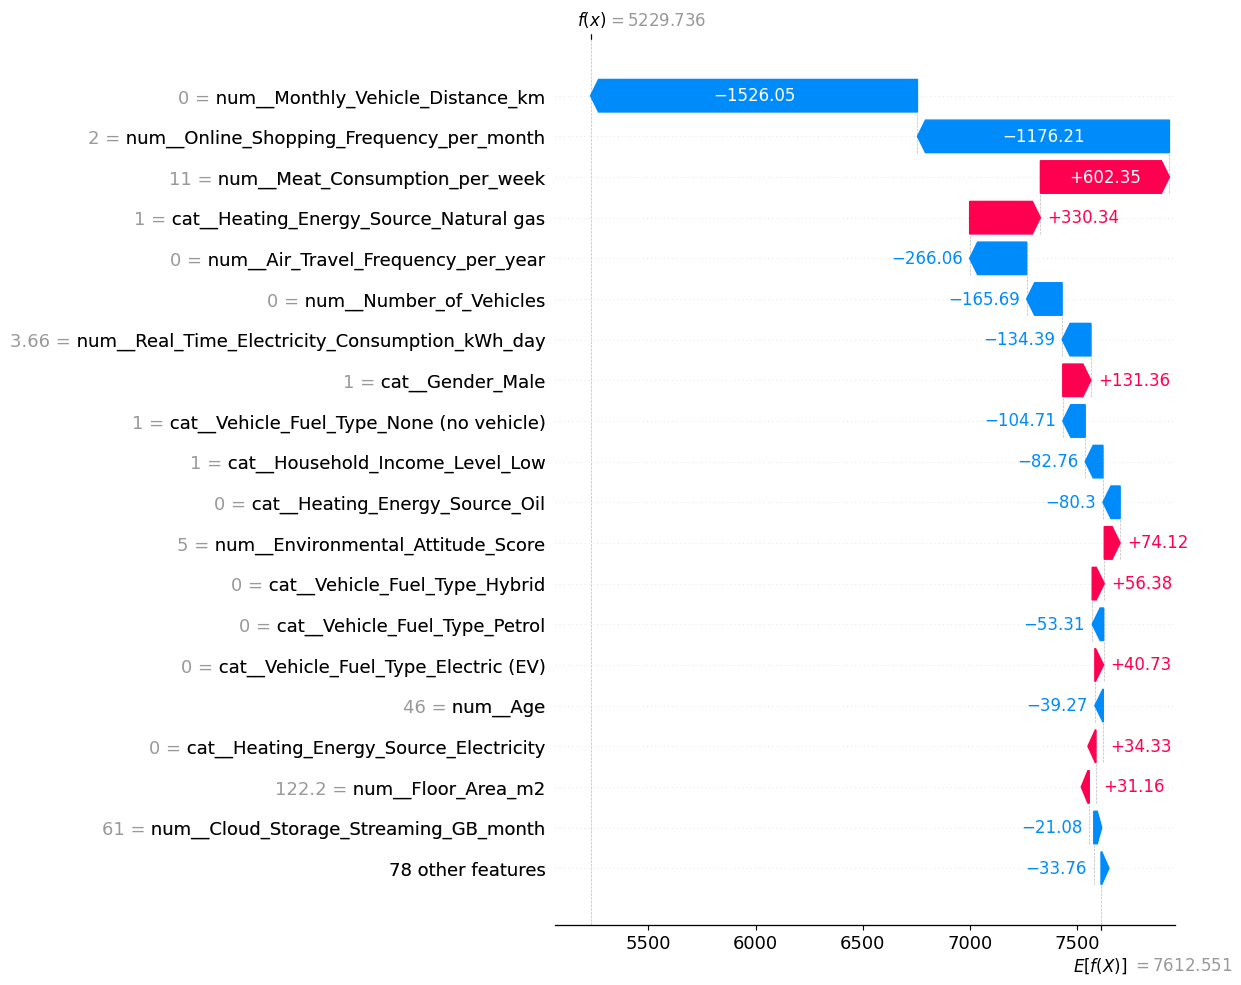

In [17]:
# Transform X_test_sample once through the *fitted* preprocessor so SHAP sees the same
# features the models were actually trained on, with proper column names.
feature_names = fitted["RandomForest"].named_steps["prep"].get_feature_names_out()

X_test_rf_transformed = fitted["RandomForest"].named_steps["prep"].transform(X_test_sample)
X_test_rf_transformed = pd.DataFrame(X_test_rf_transformed, columns=feature_names)

rf_explainer = shap.TreeExplainer(fitted["RandomForest"].named_steps["model"])
rf_shap_values = rf_explainer(X_test_rf_transformed, check_additivity=False)

shap.plots.beeswarm(rf_shap_values, max_display=20)

rf_importance = pd.Series(
    np.abs(rf_shap_values.values).mean(axis=0), index=feature_names
).sort_values(ascending=False)
print("\nTop 20 features driving Carbon_Footprint_kgCO2_year (RandomForest):\n")
print(rf_importance.head(20))

shap.plots.waterfall(rf_shap_values[0], max_display=20)

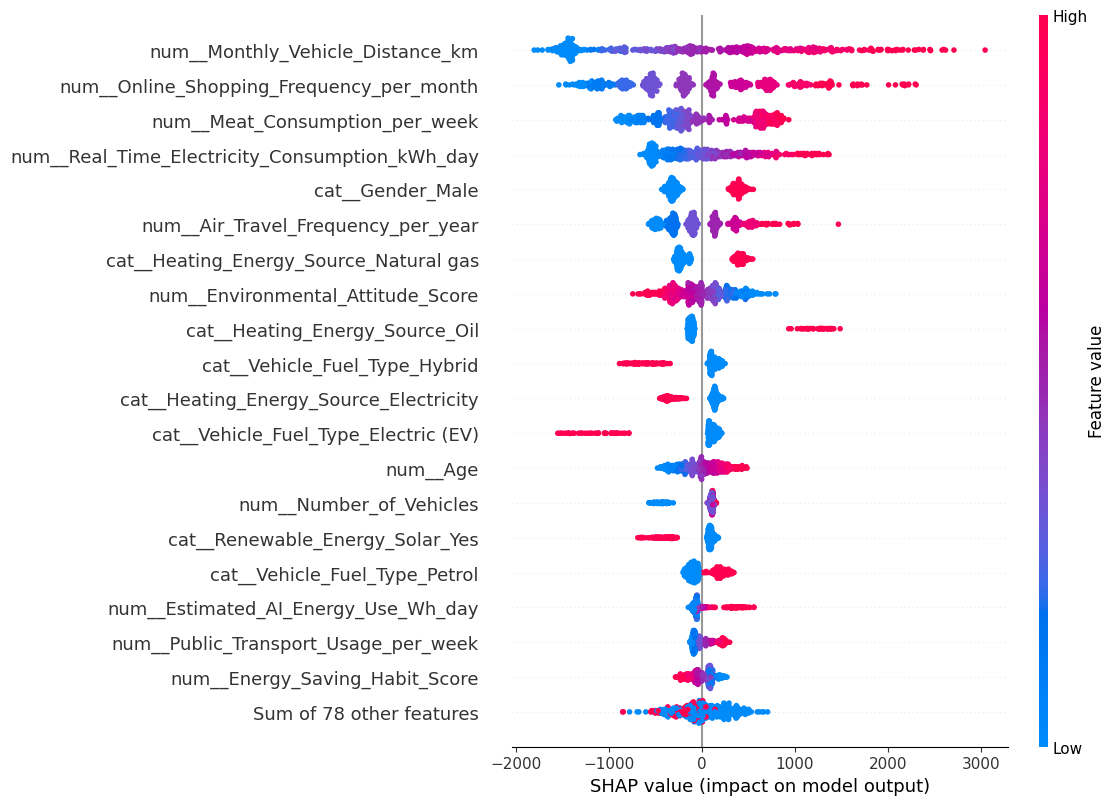


Top 20 features driving Carbon_Footprint_kgCO2_year (XGBoost):

num__Monthly_Vehicle_Distance_km                  946.771179
num__Online_Shopping_Frequency_per_month          694.536377
num__Meat_Consumption_per_week                    472.317169
num__Real_Time_Electricity_Consumption_kWh_day    399.820068
cat__Gender_Male                                  346.605957
num__Air_Travel_Frequency_per_year                312.919281
cat__Heating_Energy_Source_Natural gas            292.032135
num__Environmental_Attitude_Score                 246.865417
cat__Heating_Energy_Source_Oil                    218.449127
cat__Vehicle_Fuel_Type_Hybrid                     218.040512
cat__Heating_Energy_Source_Electricity            205.957306
cat__Vehicle_Fuel_Type_Electric (EV)              204.449234
num__Age                                          173.425079
num__Number_of_Vehicles                           170.559708
cat__Renewable_Energy_Solar_Yes                   158.573914
cat__Vehicle_Fuel_Ty

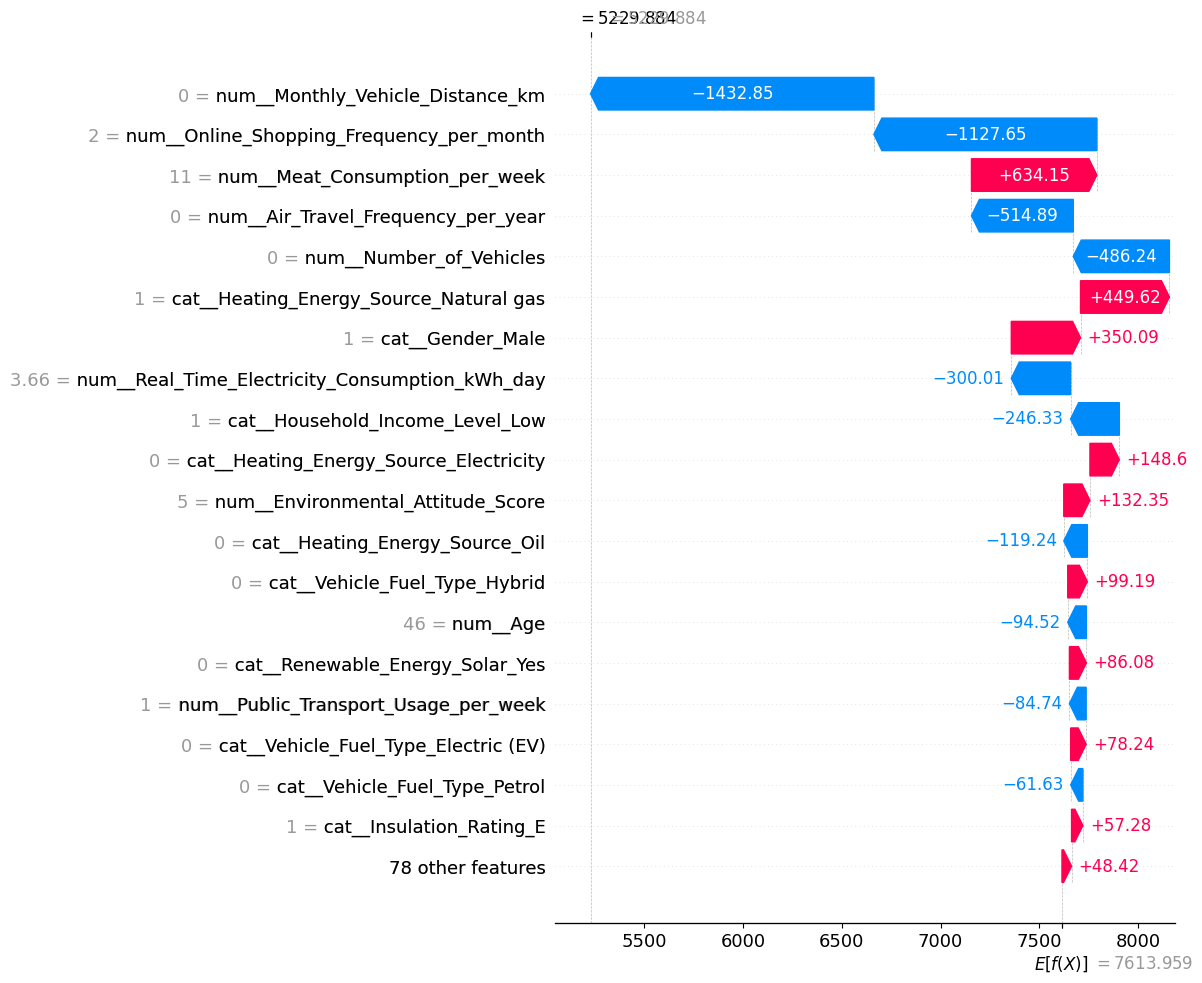

In [18]:
X_test_xgb_transformed = fitted["XGBoost"].named_steps["prep"].transform(X_test_sample)
X_test_xgb_transformed = pd.DataFrame(X_test_xgb_transformed, columns=feature_names)

xgb_explainer = shap.TreeExplainer(fitted["XGBoost"].named_steps["model"])
xgb_shap_values = xgb_explainer(X_test_xgb_transformed, check_additivity=False)

shap.plots.beeswarm(xgb_shap_values, max_display=20)

xgb_importance = pd.Series(
    np.abs(xgb_shap_values.values).mean(axis=0), index=feature_names
).sort_values(ascending=False)
print("\nTop 20 features driving Carbon_Footprint_kgCO2_year (XGBoost):\n")
print(xgb_importance.head(20))

shap.plots.waterfall(xgb_shap_values[0], max_display=20)

SHAP's `TreeExplainer` doesn't apply to the MLP (it isn't a tree model), and the slower `KernelExplainer` route isn't worth the runtime here. **Permutation importance** gives a comparable, model-agnostic view instead — it measures how much test-set R² drops when each feature's values are shuffled.

In [19]:
perm = permutation_importance(
    fitted["NeuralNet (MLP)"], X_test_sample, y_test.loc[X_test_sample.index],
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1, scoring="r2"
)

perm_importance = pd.Series(perm.importances_mean, index=X_test_sample.columns).sort_values(ascending=False)
print("Top 20 features driving Carbon_Footprint_kgCO2_year (MLP, permutation importance):\n")
print(perm_importance.head(20))

Top 20 features driving Carbon_Footprint_kgCO2_year (MLP, permutation importance):

Monthly_Vehicle_Distance_km                  0.501752
Online_Shopping_Frequency_per_month          0.218654
Heating_Energy_Source                        0.199524
Vehicle_Fuel_Type                            0.150654
Real_Time_Electricity_Consumption_kWh_day    0.127038
Meat_Consumption_per_week                    0.048665
Gender                                       0.038409
Air_Travel_Frequency_per_year                0.034544
Household_Income_Level                       0.032277
Environmental_Attitude_Score                 0.030284
Renewable_Energy_Solar                       0.023390
Age                                          0.022320
Public_Transport_Usage_per_week              0.013855
Diet_Type                                    0.012104
AI_Model_Type                                0.009972
Estimated_AI_Energy_Use_Wh_day               0.006672
Energy_Saving_Habit_Score                    0.00604

### 7. Residual Diagnostics

Checks whether the best model is systematically over- or under-predicting at certain ranges of the target — something the R²/MAE/RMSE summary numbers alone don't show.

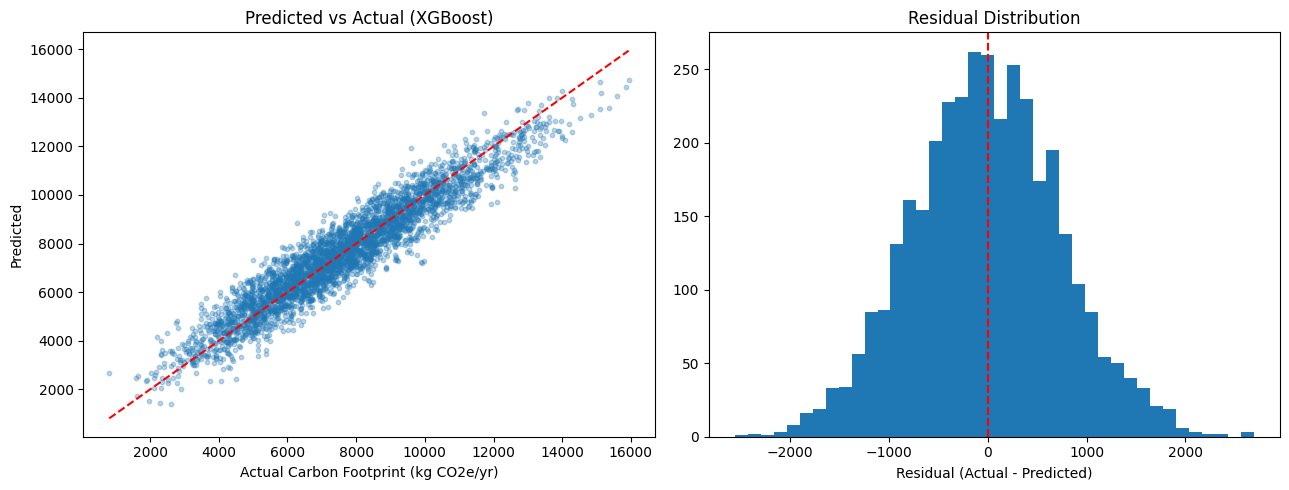

In [20]:
best_pipe = fitted[best_name]
y_pred_best = best_pipe.predict(X_test)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.3, s=10)
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
axes[0].plot(lims, lims, color="red", linestyle="--")
axes[0].set_xlabel("Actual Carbon Footprint (kg CO2e/yr)")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Predicted vs Actual ({best_name})")

axes[1].hist(residuals, bins=40)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

### 8. Visualizations

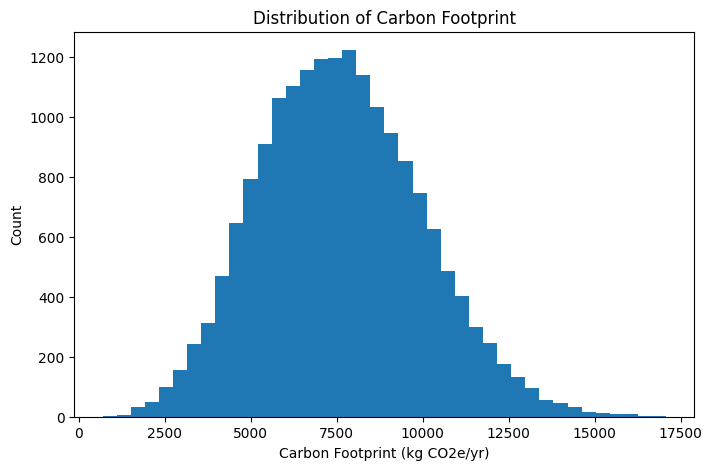

In [21]:
plt.figure(figsize=(8, 5))
plt.hist(data["Carbon_Footprint_kgCO2_year"], bins=40)
plt.xlabel("Carbon Footprint (kg CO2e/yr)")
plt.ylabel("Count")
plt.title("Distribution of Carbon Footprint")
plt.show()

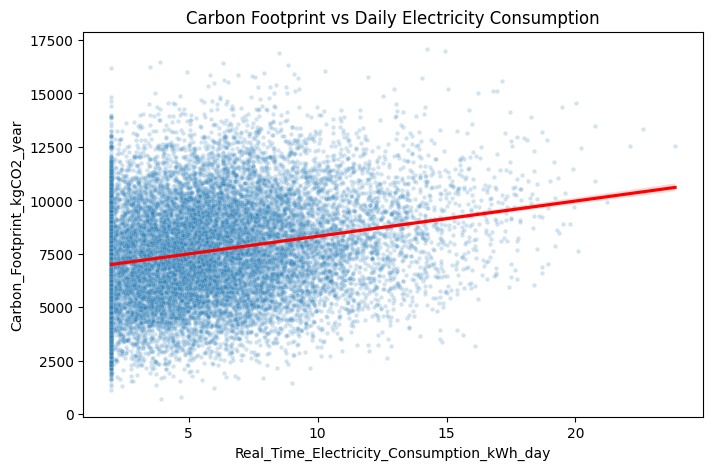

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Real_Time_Electricity_Consumption_kWh_day", y="Carbon_Footprint_kgCO2_year",
                data=data, alpha=0.2, s=10)
sns.regplot(x="Real_Time_Electricity_Consumption_kWh_day", y="Carbon_Footprint_kgCO2_year",
            data=data, scatter=False, color="red")
plt.title("Carbon Footprint vs Daily Electricity Consumption")
plt.show()

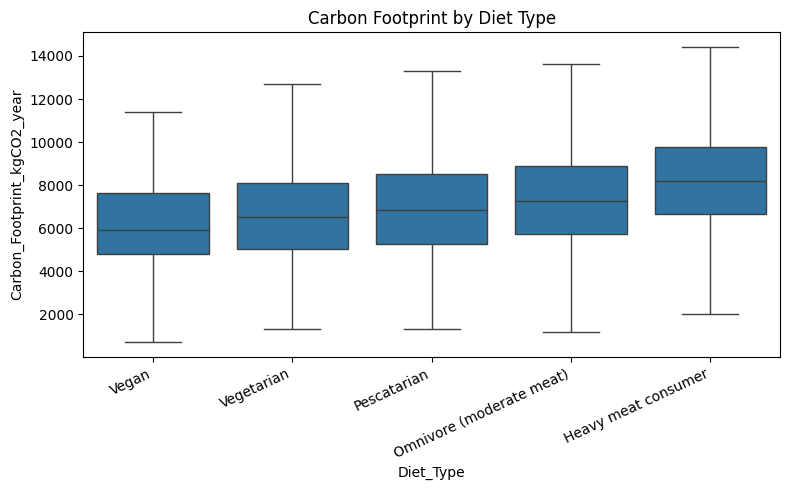

In [23]:
plt.figure(figsize=(8, 5))
order = data.groupby("Diet_Type")["Carbon_Footprint_kgCO2_year"].median().sort_values().index
sns.boxplot(x="Diet_Type", y="Carbon_Footprint_kgCO2_year", data=data, order=order, showfliers=False)
plt.xticks(rotation=25, ha="right")
plt.title("Carbon Footprint by Diet Type")
plt.tight_layout()
plt.show()

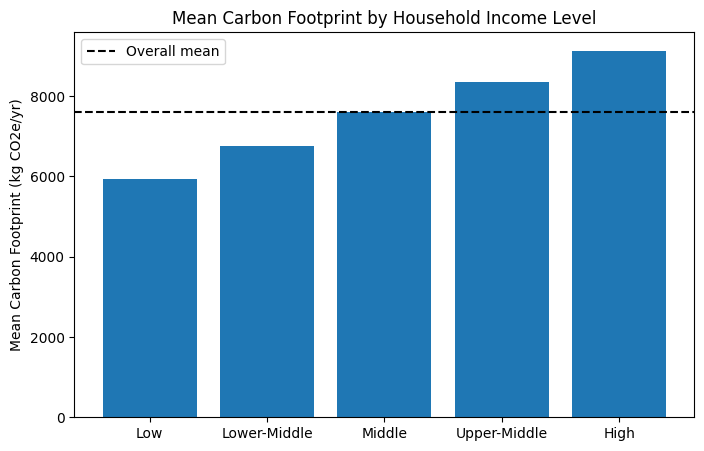

In [24]:
plt.figure(figsize=(8, 5))
order = ["Low", "Lower-Middle", "Middle", "Upper-Middle", "High"]
means = data.groupby("Household_Income_Level")["Carbon_Footprint_kgCO2_year"].mean().reindex(order)
plt.bar(means.index, means.values)
plt.axhline(data["Carbon_Footprint_kgCO2_year"].mean(), color="black", linestyle="--", label="Overall mean")
plt.ylabel("Mean Carbon Footprint (kg CO2e/yr)")
plt.title("Mean Carbon Footprint by Household Income Level")
plt.legend()
plt.show()

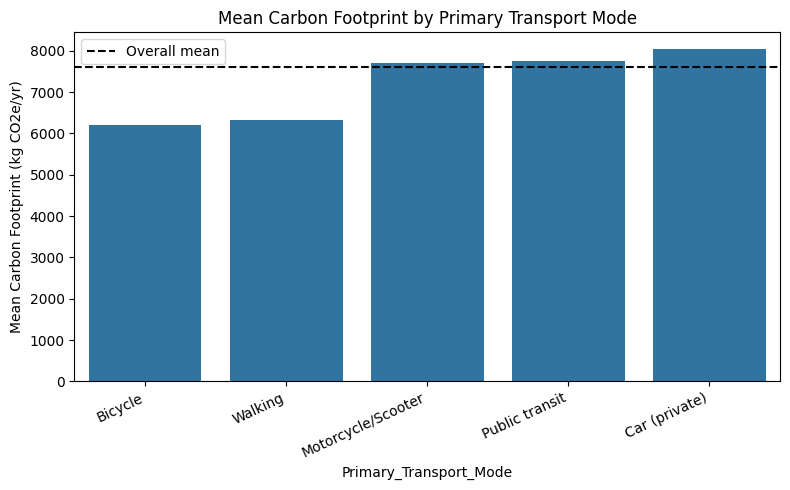

In [25]:
plt.figure(figsize=(8, 5))
means = data.groupby("Primary_Transport_Mode")["Carbon_Footprint_kgCO2_year"].mean().sort_values()
sns.barplot(x=means.index, y=means.values)
plt.axhline(data["Carbon_Footprint_kgCO2_year"].mean(), color="black", linestyle="--", label="Overall mean")
plt.xticks(rotation=25, ha="right")
plt.ylabel("Mean Carbon Footprint (kg CO2e/yr)")
plt.title("Mean Carbon Footprint by Primary Transport Mode")
plt.legend()
plt.tight_layout()
plt.show()

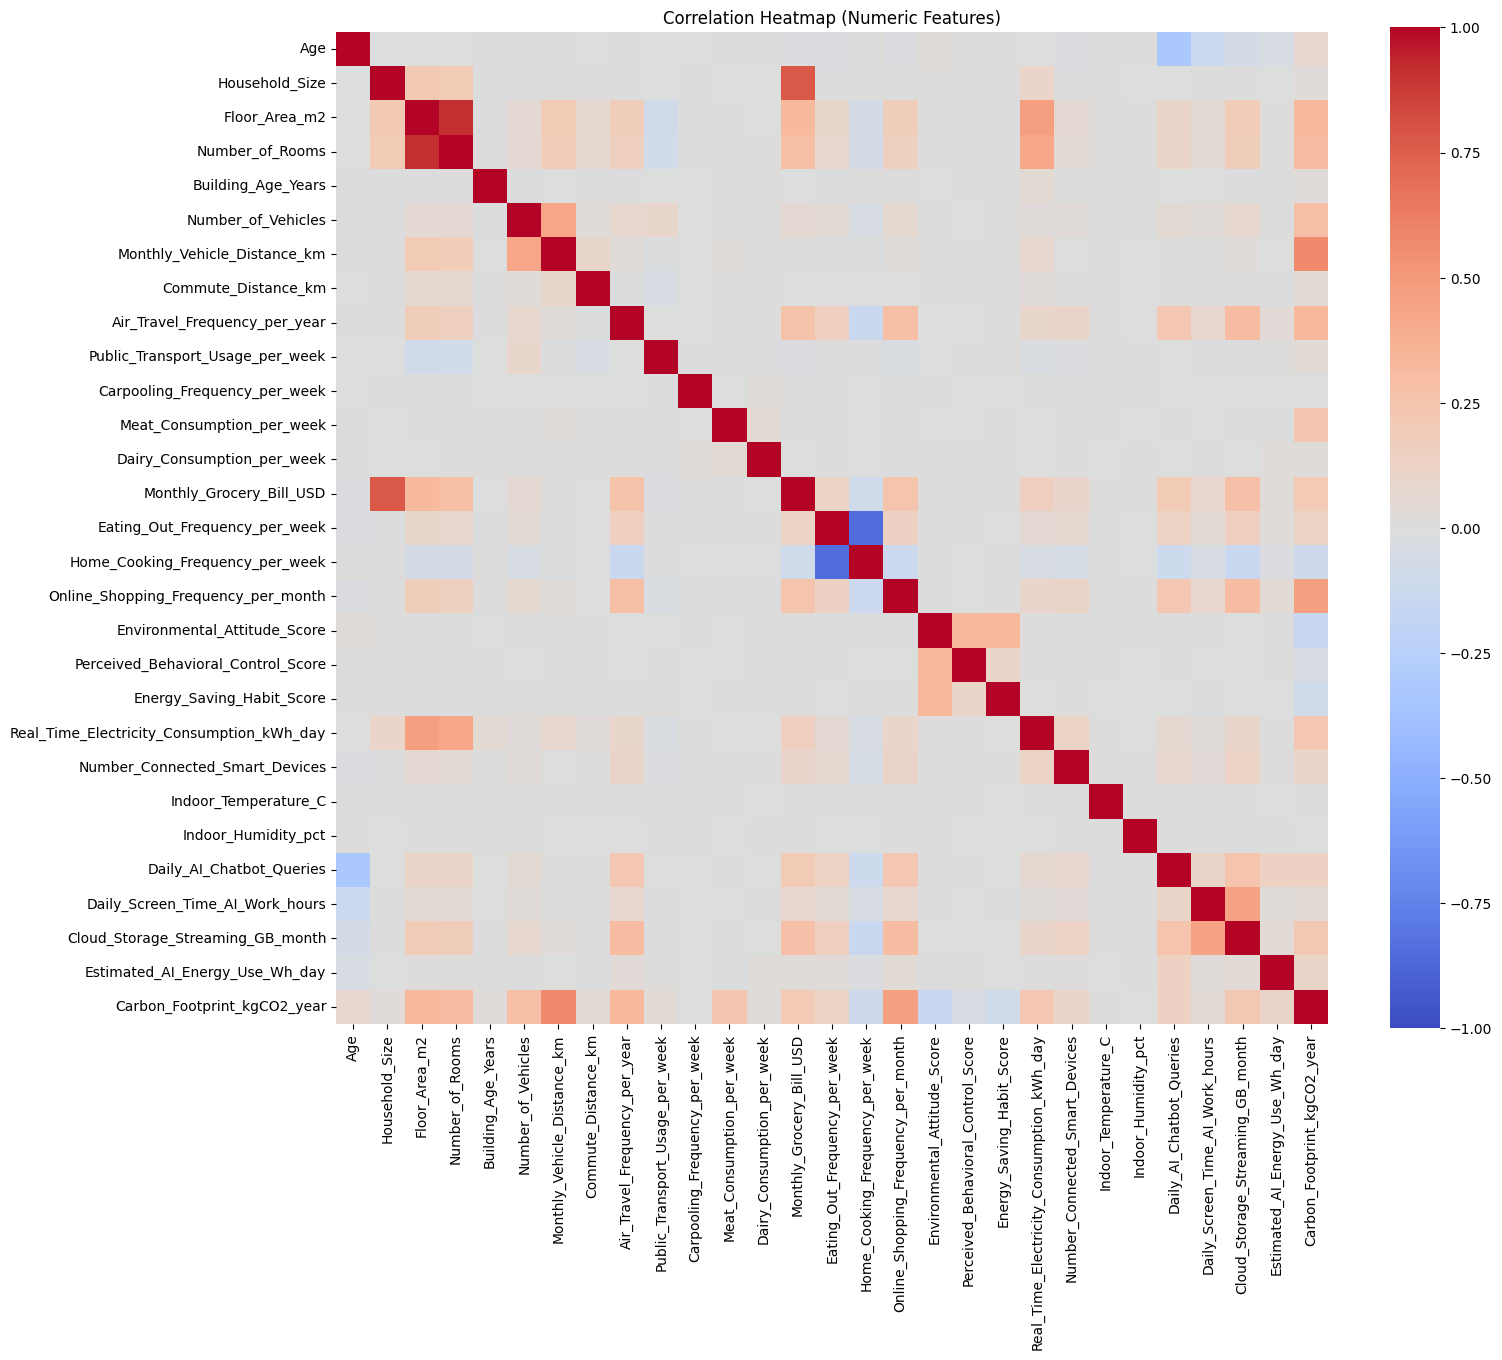

In [26]:
# Correlation heatmap - fixed to vmin=-1 so negative correlations show correctly
# (the original notebook used vmin=0, which flattened all negative correlations
# to look identical to "no correlation")
numeric_for_corr = data[numeric_cols + ["Carbon_Footprint_kgCO2_year"]]
corr = numeric_for_corr.corr(numeric_only=True)

plt.figure(figsize=(16, 13))
sns.heatmap(corr, annot=False, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True, square=True)
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()

### 9. Save the Best Model

Saves the full pipeline (preprocessing + model together), so it can be loaded later and called directly on raw, uncleaned input rows — no need to re-run any of the cleaning steps by hand.

In [27]:
model_path = f"best_model_{best_name.replace(' ', '_').replace('(', '').replace(')', '')}.pkl"
joblib.dump(best_pipe, model_path)
print(f"Saved best model ({best_name}) to {model_path}")

# Example of loading and using it later:
# loaded_pipe = joblib.load(model_path)
# loaded_pipe.predict(new_raw_dataframe)

Saved best model (XGBoost) to best_model_XGBoost.pkl
